# Fermi-Hubbard 1D: Jordan-Wigner verification notebook

This notebook walks through the `FermiHubbard1D` implementation 

The two JW orderings — **stacked** (`[↑_0...↑_{L-1}, ↓_0...↓_{L-1}]`) and **interleaved** (`[↑_0, ↓_0, ↑_1, ↓_1, ...]`)

Verification:
1. Hermiticity 
2. Choice of encoding doesn't affect spectrum 
3. GS energy matches analytical result ($N=2$, arbitrary $t$ and $U$)
4. Spectrum matches analysis result ($U=0$, arbitrary $N$ and $t$, PBC)
5. For $U=0$, up and down spins unentangled in stacked order but entangled in interleaved order
6. Entanglement profile of ground state at $U=0$ for the two orders 
5. Electron-number symmetry — tests number conservation
6. Trotter convergence — tests the Trotterization grouping

In [ ]:
import warnings 
warnings.filterwarnings("ignore")

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

from qaravan.applications import (
    trotter_circuit, fermionic_ground_state, fermionic_spectrum, entanglement_profile
)
from qaravan.core.fermions import FermionicEncoding, interleaved_mode_order
from qaravan.core.hamiltonians import FermiHubbard1D
from qaravan.backends.statevector import Statevector, StatevectorSimulator
from qaravan.core.observables import Magnetization, NumberOperator
from qaravan.plot import set_style

set_style()


def fh_encoding(num_fermionic_sites: int, ordering: str) -> FermionicEncoding:
    """The two named qubit layouts, as FermionicEncodings."""
    mode_order = (
        None if ordering == "stacked" else interleaved_mode_order(num_fermionic_sites)
    )
    return FermionicEncoding(
        "jordan_wigner", num_modes=2 * num_fermionic_sites, mode_order=mode_order
    )

## 1. Shape and Hermiticity

For `num_fermionic_sites=L`, both orderings produce a `2L`-qubit system (one qubit per fermionic mode). The Hamiltonian matrix is `2^(2L) × 2^(2L)`. Here `L=3` gives 6 qubits → 64×64.

**Check:** `H = H†` to machine precision. 

In [2]:
fh = FermiHubbard1D(num_fermionic_sites=3, t=1.0, U=2.0, mu=0.0)
ham_s = fh.encode(fh_encoding(3, "stacked"))
ham_i = fh.encode(fh_encoding(3, "interleaved"))

H_s = ham_s.to_matrix()
H_i = ham_i.to_matrix()

print(f"stacked    H shape: {H_s.shape}")
print(f"interleaved H shape: {H_i.shape}")
print()
print(f"stacked    max|H - H†|: {np.max(np.abs(H_s - H_s.conj().T)):.2e}")
print(f"interleaved max|H - H†|: {np.max(np.abs(H_i - H_i.conj().T)):.2e}")

stacked    H shape: (64, 64)
interleaved H shape: (64, 64)

stacked    max|H - H†|: 0.00e+00
interleaved max|H - H†|: 0.00e+00


## 2. Encoding leaves spectrum invariant

Both orderings are unitary isomorphisms of the same Hilbert space: `H_interleaved = U H_stacked U†` for some permutation unitary `U`. The full spectrum is therefore identical, to machine precision, for any `(t, U)`. 

In [3]:
params = [(1.0, 0.0), (1.0, 2.0), (0.5, 4.0), (2.0, 1.0)]

print(f"{'t':>6}  {'U':>6}  {'E0 stacked':>14}  {'E0 interleaved':>16}  {'max |diff|':>12}")
print("-" * 62)
for t, U in params:
    fh = FermiHubbard1D(num_fermionic_sites=3, t=t, U=U, mu=0.0)
    E_s = fermionic_spectrum(fh, fh_encoding(3, "stacked"), num_eigenvalues=5)
    E_i = fermionic_spectrum(fh, fh_encoding(3, "interleaved"), num_eigenvalues=5)
    diff = np.max(np.abs(E_s - E_i))
    print(f"{t:>6.2f}  {U:>6.2f}  {E_s[0]:>14.8f}  {E_i[0]:>16.8f}  {diff:>12.2e}")

     t       U      E0 stacked    E0 interleaved    max |diff|
--------------------------------------------------------------
  1.00    0.00     -2.82842712       -2.82842712      1.78e-15
  1.00    2.00     -2.27945232       -2.27945232      2.66e-15
  0.50    4.00     -0.87740375       -0.87740375      1.27e-14
  2.00    1.00     -5.31004128       -5.31004128      7.99e-15


## 3. Analytical ground state energy for Hubbard dimer

For `2` sites at half-filling (`fixed_particle_number=2`), the Hubbard dimer ground-state energy has an exact closed form derivable from the 4×4 Hamiltonian restricted to the two-particle sector:

$$E_\mathrm{gs} = \frac{U - \sqrt{U^2 + 16t^2}}{2}$$

In [4]:
test_cases = [(1.0, 2.0), (0.5, 4.0), (1.0, 0.0)]

print(f"{'t':>5}  {'U':>5}  {'E_exact':>12}  {'stacked':>12}  {'interleaved':>12}  {'err_s':>10}  {'err_i':>10}")
print("-" * 80)
for t, U in test_cases:
    E_exact = (U - np.sqrt(U**2 + 16 * t**2)) / 2
    fh = FermiHubbard1D(num_fermionic_sites=2, t=t, U=U, mu=0.0)
    for ordering in ["stacked", "interleaved"]:
        energy = fermionic_spectrum(fh, 
                                    fh_encoding(2, ordering), 
                                    num_eigenvalues=1, 
                                    fixed_particle_number=2)[0]
        
        err = abs(energy - E_exact)
        if ordering == "stacked":
            E_s, err_s = energy, err
        else:
            print(f"{t:>5.2f}  {U:>5.2f}  {E_exact:>12.8f}  {E_s:>12.8f}  {energy:>12.8f}  {err_s:>10.2e}  {err:>10.2e}")

    t      U       E_exact       stacked   interleaved       err_s       err_i
--------------------------------------------------------------------------------
 1.00   2.00   -1.23606798   -1.23606798   -1.23606798    2.22e-16    4.44e-16
 0.50   4.00   -0.23606798   -0.23606798   -0.23606798    8.33e-17    8.33e-17
 1.00   0.00   -2.00000000   -2.00000000   -2.00000000    0.00e+00    0.00e+00


## 4. Free-fermionic limit

### Spectrum


At `U=0` the model decouples into two independent tight-binding chains, one per spin. For a periodic chain of `L` sites the single-particle levels are:

$$\varepsilon_k = -2t \cos\!\left(\frac{2 \pi k}{L}\right), \quad k = 0, \ldots, L-1$$

In [5]:
num_fermionic_sites = 4
t = 1.0

tb_levels = sorted(-2 * t * np.cos(2 * np.pi * k / (num_fermionic_sites)) for k in range(0, num_fermionic_sites))
print("Tight-binding single-particle levels (one spin):")
print([f"{e:.5f}" for e in tb_levels])

fh = FermiHubbard1D(num_fermionic_sites=num_fermionic_sites, t=t, U=0.0, mu=0.0, periodic=True)
spect_s = fermionic_spectrum(fh, fh_encoding(num_fermionic_sites, "stacked"), fixed_particle_number=1)
spect_i = fermionic_spectrum(fh, fh_encoding(num_fermionic_sites, "interleaved"), fixed_particle_number=1)
print("Tight-binding vs Fermi-Hubbard spectrum (stacked ordering, U=0):")
print([f"{e:.5f}" for e in spect_s])
print("Tight-binding vs Fermi-Hubbard spectrum (interleaved ordering, U=0):")
print([f"{e:.5f}" for e in spect_i])

Tight-binding single-particle levels (one spin):
['-2.00000', '-0.00000', '0.00000', '2.00000']
Tight-binding vs Fermi-Hubbard spectrum (stacked ordering, U=0):
['-2.00000', '-2.00000', '0.00000', '0.00000', '0.00000', '0.00000', '2.00000', '2.00000']
Tight-binding vs Fermi-Hubbard spectrum (interleaved ordering, U=0):
['-2.00000', '-2.00000', '-0.00000', '-0.00000', '-0.00000', '0.00000', '2.00000', '2.00000']


## 5. Electron number conservation

`[H, N] = 0` where `N = sum_k (I - Z_k)/2` is the total electron number operator. Both encodings must conserve electron number: the ground state in the fixed-`N=n_electrons` sector must satisfy `<N> = n_electrons` exactly.

This catches particle-number-violating terms — e.g. if a hopping term was missing its h.c., it would create or destroy electrons.

In [6]:
num_fermionic_sites = 3
num_qubits = 2 * num_fermionic_sites

n_op = NumberOperator(num_qubits)
fh = FermiHubbard1D(num_fermionic_sites=num_fermionic_sites, t=1.0, U=2.0, mu=0.0)
for ordering in ["stacked", "interleaved"]:
    for n_elec in [2, 3, 4]:
        sv = fermionic_ground_state(fh, fh_encoding(num_fermionic_sites, ordering), fixed_particle_number=n_elec)
        expected_N = sv.expectation(n_op)
        err = abs(expected_N - n_elec)
        print(f"{ordering:>12}  {n_elec:>8}  {expected_N:>14.10f}  {err:>16.2e}")

     stacked         2  2.0000000000+0.0000000000j          2.44e-15
     stacked         3  3.0000000000+0.0000000000j          3.11e-15
     stacked         4  4.0000000000+0.0000000000j          3.55e-15
 interleaved         2  2.0000000000+0.0000000000j          2.44e-15
 interleaved         3  3.0000000000+0.0000000000j          1.78e-15
 interleaved         4  4.0000000000+0.0000000000j          1.78e-15


## 6. Trotter error scaling 

At `dt → 0`, the one-step Frobenius error between `U_Trotter(dt)` and `e^{-i H dt}` should scale as:
- `O(dt^2)` for order-1 (first-order Suzuki-Trotter)
- `O(dt^3)` for order-2 (symmetric/second-order)

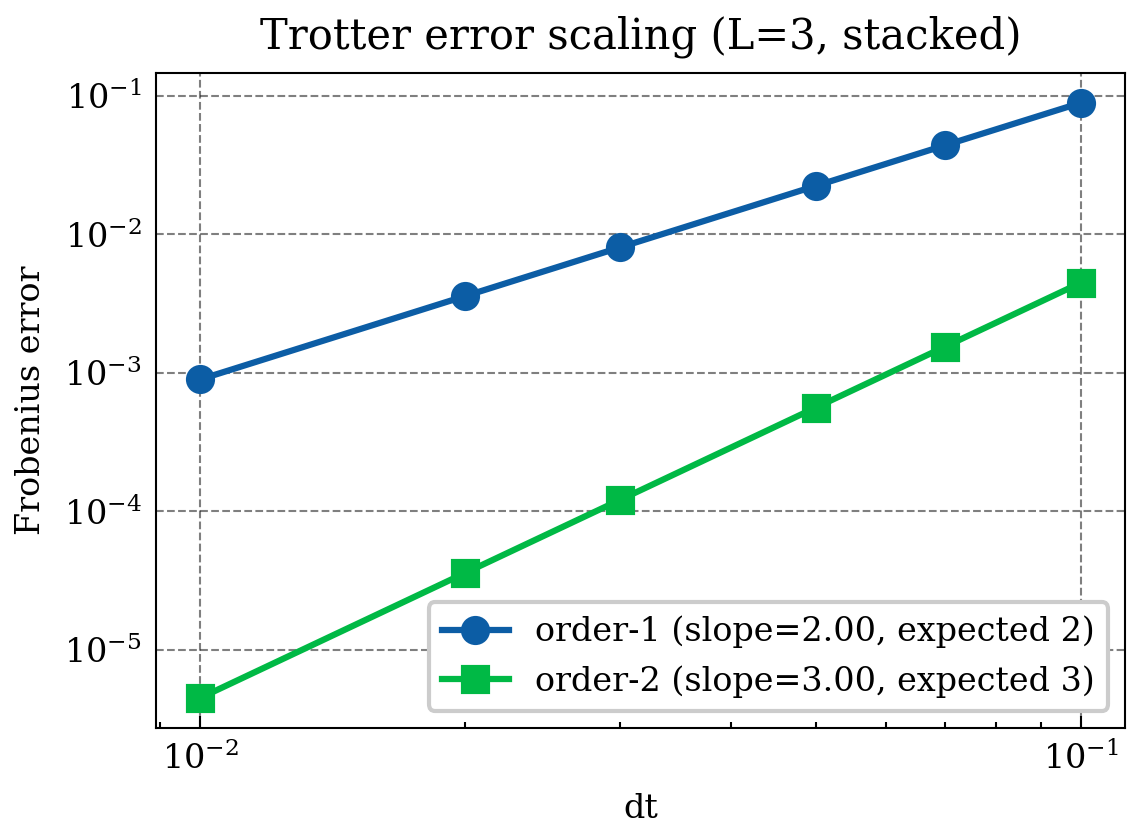

In [7]:
num_fermionic_sites = 3
fh = FermiHubbard1D(num_fermionic_sites=num_fermionic_sites, t=1.0, U=2.0, mu=0.0)
ham = fh.encode(fh_encoding(num_fermionic_sites, "stacked"))

fig, axes = plt.subplots(1, 1, figsize=(4, 3))
dt_values = np.array([0.1, 0.07, 0.05, 0.03, 0.02, 0.01])
H_mat = ham.to_matrix()

errors_order1, errors_order2 = [], []
for dt in dt_values:
    exact_prop = expm(-1j * dt * H_mat)
    trotter1 = trotter_circuit(ham, dt, order=1).to_matrix()
    trotter2 = trotter_circuit(ham, dt, order=2).to_matrix()
    errors_order1.append(np.linalg.norm(trotter1 - exact_prop, ord="fro"))
    errors_order2.append(np.linalg.norm(trotter2 - exact_prop, ord="fro"))

slope1 = np.polyfit(np.log(dt_values), np.log(errors_order1), 1)[0]
slope2 = np.polyfit(np.log(dt_values), np.log(errors_order2), 1)[0]

axes.loglog(dt_values, errors_order1, "o-", label=f"order-1 (slope={slope1:.2f}, expected 2)")
axes.loglog(dt_values, errors_order2, "s-", label=f"order-2 (slope={slope2:.2f}, expected 3)")
axes.set_xlabel("dt")
axes.set_ylabel("Frobenius error")
axes.set_title("Trotter error scaling (L=3, stacked)")
axes.legend()

plt.tight_layout()

## 7. Periodic boundary conditions

`periodic=True` adds the wrap-around bond. Under Jordan-Wigner that bond is not local: its
parity string stretches across the whole register, which is the one structurally new thing
PBC introduces.

### 7.1 Boundary term structure

Inspect the terms added by `periodic=True` and verify their site lists and Pauli strings.

In [8]:
from collections import Counter


def term_key(term):
    """Content fingerprint of a HamiltonianTerm.

    A positional slice terms[len(obc):] does NOT isolate the boundary bonds: PBC adds them to
    the existing hopping Trotter groups, so the tail of the list is onsite terms.
    """
    paulis = tuple(
        sorted(
            (p.string, round(p.coeff.real, 12), round(p.coeff.imag, 12))
            for p in term.local_obs.terms
        )
    )
    return tuple(term.sites), paulis


L = 3
for ordering in ["stacked", "interleaved"]:
    ham_obc = FermiHubbard1D(L, t=1.0, U=1.0, periodic=False).encode(fh_encoding(L, ordering))
    ham_pbc = FermiHubbard1D(L, t=1.0, U=1.0, periodic=True).encode(fh_encoding(L, ordering))
    extra = Counter(map(term_key, ham_pbc.terms)) - Counter(map(term_key, ham_obc.terms))
    print(f"\n{ordering} — boundary terms added by PBC:")
    for sites, paulis in extra:
        for string, coeff, _ in paulis:
            print(f"  sites={list(sites)}  Pauli='{string}'  coeff={coeff:.3f}")


stacked — boundary terms added by PBC:
  sites=[0, 1, 2]  Pauli='XZX'  coeff=-0.500
  sites=[0, 1, 2]  Pauli='YZY'  coeff=-0.500
  sites=[3, 4, 5]  Pauli='XZX'  coeff=-0.500
  sites=[3, 4, 5]  Pauli='YZY'  coeff=-0.500

interleaved — boundary terms added by PBC:
  sites=[0, 1, 2, 3, 4]  Pauli='XZZZX'  coeff=-0.500
  sites=[0, 1, 2, 3, 4]  Pauli='YZZZY'  coeff=-0.500
  sites=[1, 2, 3, 4, 5]  Pauli='XZZZX'  coeff=-0.500
  sites=[1, 2, 3, 4, 5]  Pauli='YZZZY'  coeff=-0.500


**Expected (stacked, L=3):**  
↑ boundary: sites `[0,1,2]`, Paulis `XZX` and `YZY` with coeff −0.5  
↓ boundary: sites `[3,4,5]`, same Paulis  

**Expected (interleaved, L=3):**  
↑ boundary: sites `[0,1,2,3,4]`, Paulis `XZZZX` and `YZZZY` with coeff −0.5  
↓ boundary: sites `[1,2,3,4,5]`, same Paulis

### 7.2 OBC vs PBC spectrum

PBC lowers the ground-state energy (ring has more hopping channels).
Stacked and interleaved must agree on each.

In [9]:
print(f"{'L':>3}  {'ordering':>12}  {'E0 OBC':>10}  {'E0 PBC':>10}  {'ΔE':>8}")
print("-" * 52)
for L in [2, 3, 4]:
    for ordering in ["stacked", "interleaved"]:
        fh_o = FermiHubbard1D(L, t=1.0, U=2.0, periodic=False)
        fh_p = FermiHubbard1D(L, t=1.0, U=2.0, periodic=True)
        ham_o = fh_o.encode(fh_encoding(L, ordering))
        ham_p = fh_p.encode(fh_encoding(L, ordering))
        E_o = np.linalg.eigvalsh(ham_o.to_matrix())[0]
        E_p = np.linalg.eigvalsh(ham_p.to_matrix())[0]
        print(f"{L:>3}  {ordering:>12}  {E_o:>10.5f}  {E_p:>10.5f}  {E_p-E_o:>8.5f}")

  L      ordering      E0 OBC      E0 PBC        ΔE
----------------------------------------------------
  2       stacked    -1.23607    -3.12311  -1.88704
  2   interleaved    -1.23607    -3.12311  -1.88704
  3       stacked    -2.27945    -3.46410  -1.18465
  3   interleaved    -2.27945    -3.46410  -1.18465


  4       stacked    -3.06954    -3.62721  -0.55768
  4   interleaved    -3.06954    -3.62721  -0.55768


**Check:** stacked and interleaved rows for the same L should agree on E0 OBC and E0 PBC to machine precision.

### 7.3 Full spectrum: OBC vs PBC

Plot the full spectrum for L=3 to see how PBC shifts all levels, not just the ground state.

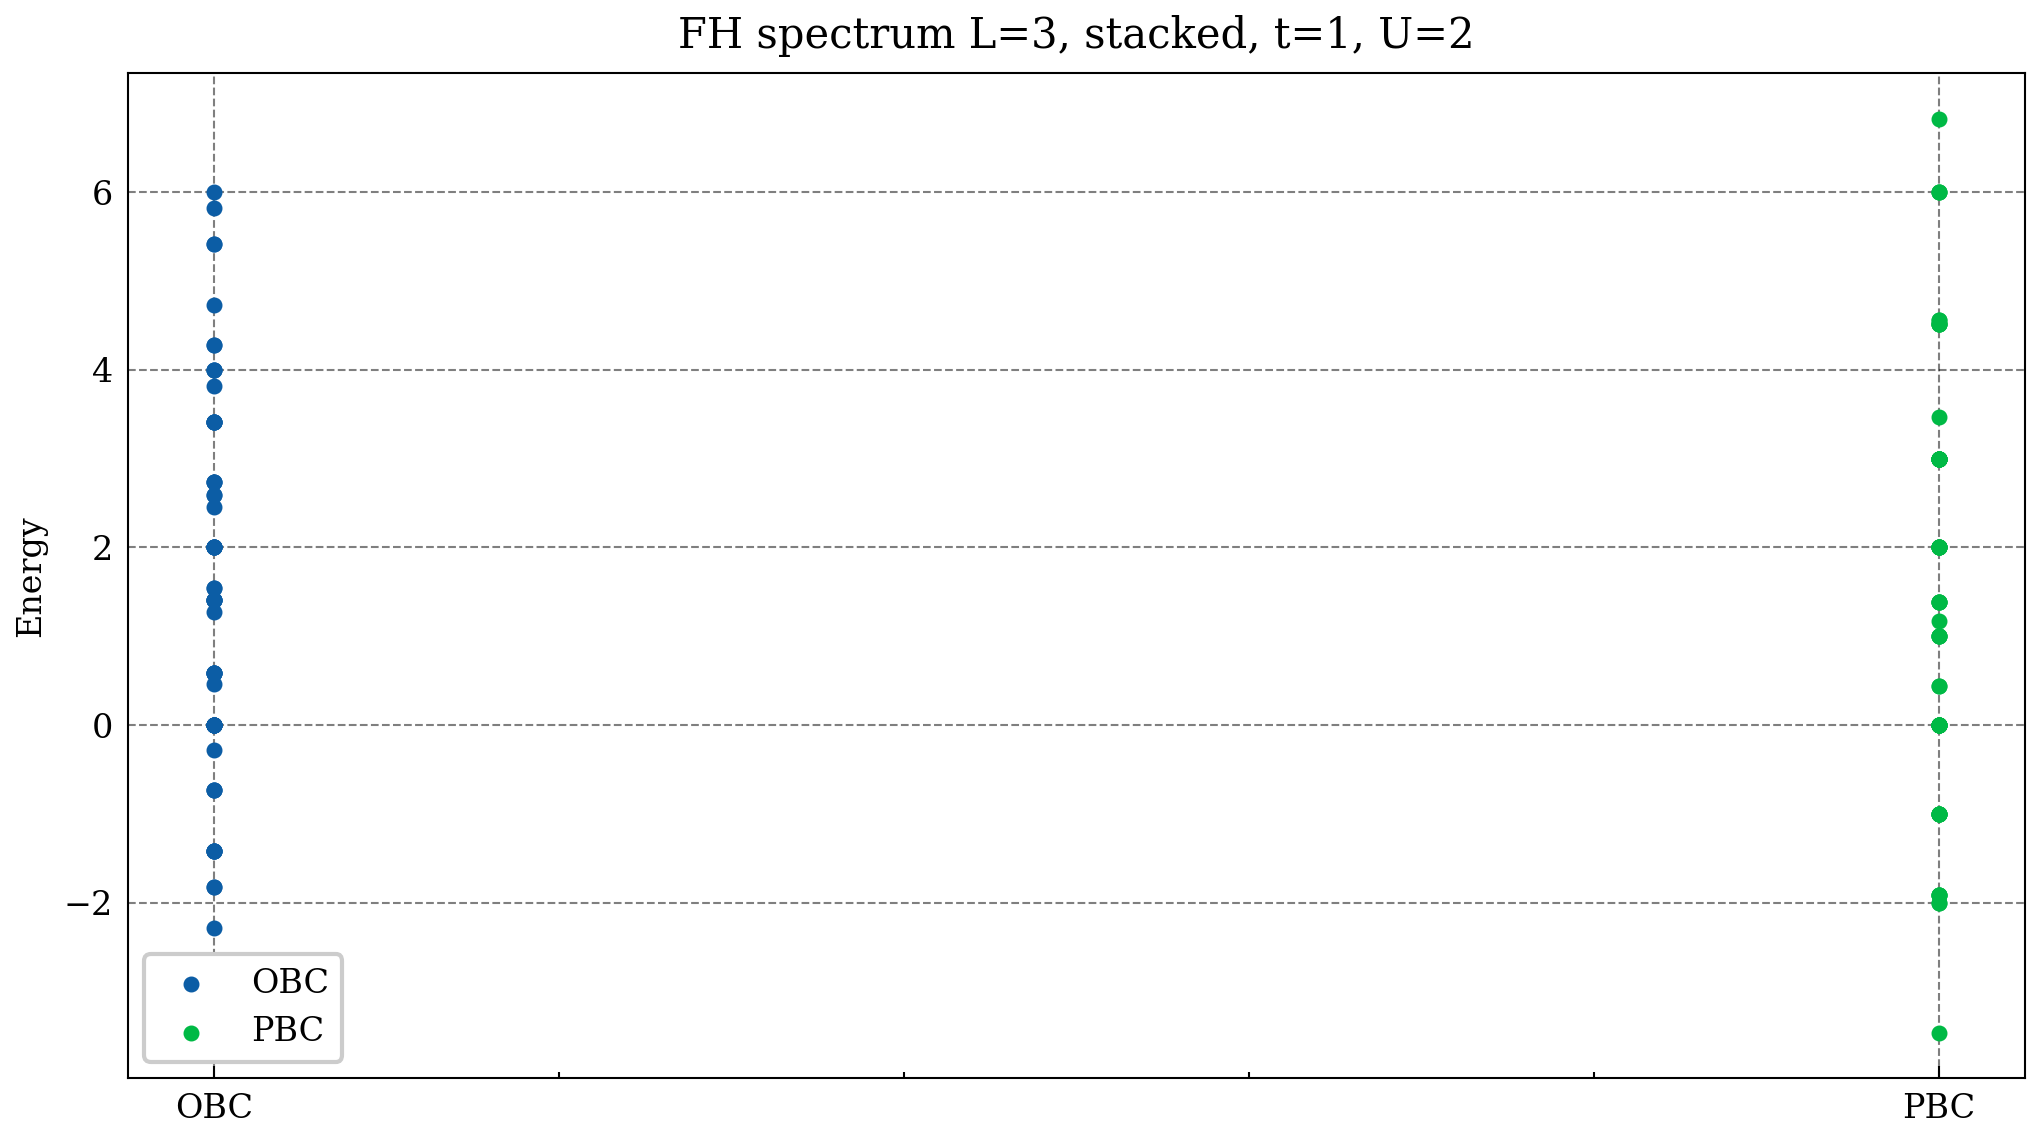

In [10]:
L = 3
fh_obc = FermiHubbard1D(L, t=1.0, U=2.0, periodic=False)
fh_pbc = FermiHubbard1D(L, t=1.0, U=2.0, periodic=True)
ham_obc = fh_obc.encode(fh_encoding(L, "stacked"))
ham_pbc = fh_pbc.encode(fh_encoding(L, "stacked"))
E_obc = np.linalg.eigvalsh(ham_obc.to_matrix())
E_pbc = np.linalg.eigvalsh(ham_pbc.to_matrix())

fig, ax = plt.subplots(figsize=(7, 4))
x_obc = np.zeros(len(E_obc))
x_pbc = np.ones(len(E_pbc))
ax.scatter(x_obc, E_obc, s=8, label="OBC")
ax.scatter(x_pbc, E_pbc, s=8, label="PBC")
ax.set_xticks([0, 1])
ax.set_xticklabels(["OBC", "PBC"])
ax.set_ylabel("Energy")
ax.set_title(f"FH spectrum L={L}, stacked, t=1, U=2")
ax.legend()
plt.tight_layout()
plt.show()

### 7.4 L=1 guard

`periodic=True` with a single fermion site has no meaningful ring topology and must raise.

In [11]:
try:
    FermiHubbard1D(1, periodic=True)
    print("ERROR: should have raised ValueError")
except ValueError as exc:
    print(f"Correctly raised ValueError: {exc}")

Correctly raised ValueError: periodic=True requires num_fermionic_sites >= 2.
